Smiley: 50.0 15.0 50.0 15.0
Sad   : 50.0 15.0 50.0 15.0


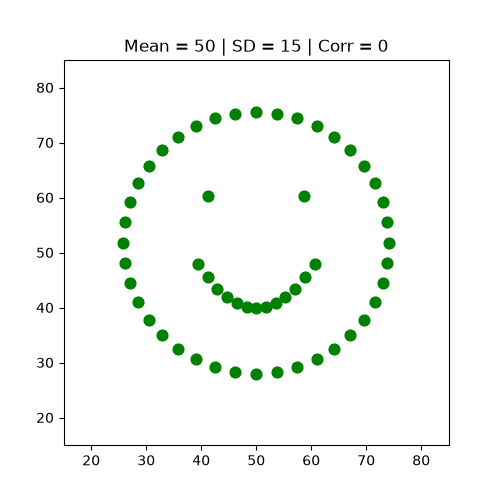

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import Image, display

# 1. Head circle (40 points) + 2 eyes + 13 mouth points = 55 points
angles = np.linspace(0, 2 * np.pi, 40, endpoint=False)
x_head = 5 * np.cos(angles)
y_head = 5 * np.sin(angles)

x_eyes = [-1.8, 1.8]
y_eyes = [1.8, 1.8]

mouth_x = np.linspace(-2.2, 2.2, 13)
smile_y = 0.35 * (mouth_x ** 2) - 2.5    # U-curve (smile)
frown_y = -0.35 * (mouth_x ** 2) - 1.0   # upside-down U (frown)

# Combine into Smiley and Sad arrays
x_smile = np.concatenate([x_head, x_eyes, mouth_x])
y_smile = np.concatenate([y_head, y_eyes, smile_y])

x_sad = x_smile.copy()
y_sad = np.concatenate([y_head, y_eyes, frown_y])

# 2. Scale both so Mean = 50 and SD = 15
x_smile = (x_smile - x_smile.mean()) / x_smile.std() * 15 + 50
y_smile = (y_smile - y_smile.mean()) / y_smile.std() * 15 + 50

x_sad = (x_sad - x_sad.mean()) / x_sad.std() * 15 + 50
y_sad = (y_sad - y_sad.mean()) / y_sad.std() * 15 + 50

print("Smiley:", round(x_smile.mean(), 1), round(x_smile.std(), 1), round(y_smile.mean(), 1), round(y_smile.std(), 1))
print("Sad   :", round(x_sad.mean(), 1), round(x_sad.std(), 1), round(y_sad.mean(), 1), round(y_sad.std(), 1))

# 3. Animate
fig, ax = plt.subplots(figsize=(5, 5))
ax.set_xlim(15, 85)
ax.set_ylim(15, 85)
ax.set_aspect("equal")  # Keeps the circle round instead of stretched!
dots = ax.scatter(x_smile, y_smile, s=60, color="green")

frames = [0]*8 + list(np.linspace(0, 1, 15)) + [1]*8 + list(np.linspace(1, 0, 15))

def update(t):
    x = (1 - t) * x_smile + t * x_sad
    y = (1 - t) * y_smile + t * y_sad
    dots.set_offsets(np.column_stack([x, y]))
    dots.set_color("red" if t > 0.5 else "green")
    ax.set_title("Mean = 50 | SD = 15 | Corr = 0")

anim = FuncAnimation(fig, update, frames=frames, interval=70)
anim.save("smile_sad.gif", writer="pillow", fps=15)
plt.close()

display(Image(filename="smile_sad.gif"))